<a href="https://colab.research.google.com/github/datadigger01/Datahandling/blob/main/Code_example/week07_EDA_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

###### 파일 읽어오기
-  https://github.com/datadigger01/Datahandling/raw/main/Data/Agent_Attrition.csv

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/데이터처리실무/Data/Agent_Attrition.csv')
df.info()
df

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2401 entries, 0 to 2400
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   AgentID           2401 non-null   int64  
 1   Tgt_3YN           2401 non-null   int64  
 2   Age_Grp           2401 non-null   object 
 3   Gender            2401 non-null   int64  
 4   Apply_CH          2401 non-null   object 
 5   re_hire_freq_grp  2401 non-null   object 
 6   Q2                2401 non-null   int64  
 7   Q7                2401 non-null   int64  
 8   Q8                2401 non-null   int64  
 9   Q18               2401 non-null   int64  
 10  Q22               2401 non-null   int64  
 11  Q38               2401 non-null   int64  
 12  rank_INDEX14      2373 non-null   float64
 13  rank_INDEX18      2373 non-null   float64
 14  rank_INDEX23      2373 non-null   float64
 15  rank_INDEX27      2373 non-null   float64
 16  rank_INDEX28      2373 non-null   float64


,AgentID,Tgt_3YN,Age_Grp,Gender,Apply_CH,re_hire_freq_grp,Q2,Q7,Q8,Q18,...,rank_INDEX14,rank_INDEX18,rank_INDEX23,rank_INDEX27,rank_INDEX28,rank_INDEX29,rank_INDEX32,rank_INDEX44,rank_INDEX93,rank_AVG_AMT_6M
0,1,1,5060G,2,Vender,1,3,1,4,2,...,2.0,0.0,2.0,0.0,0.0,2.0,0.0,0.0,2.0,6
1,2,0,40G,1,MGM,1,4,1,7,1,...,3.0,0.0,1.0,1.0,1.0,0.0,2.0,2.0,3.0,7
2,3,0,40G,2,MGM,4~,3,2,3,2,...,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5
3,4,0,40G,2,MGM,1,4,1,6,3,...,2.0,1.0,0.0,2.0,2.0,2.0,0.0,1.0,1.0,0
4,5,0,40G,2,MGM,1,2,2,5,2,...,1.0,1.0,2.0,2.0,3.0,2.0,1.0,1.0,2.0,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2396,2397,0,30G,2,MGM,0,2,2,4,2,...,3.0,2.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,7
2397,2398,0,5060G,1,MGM,0,3,2,4,2,...,3.0,0.0,2.0,1.0,1.0,0.0,0.0,0.0,0.0,5
2398,2399,0,5060G,2,MGM,0,3,2,5,2,...,1.0,1.0,1.0,2.0,2.0,1.0,0.0,0.0,3.0,4
2399,2400,0,5060G,2,MGM,0,1,1,3,3,...,0.0,3.0,3.0,3.0,2.0,3.0,3.0,3.0,3.0,5


- AgentID는 식별정보이므로 index 컬럼으로 변환

In [ ]:
df = df.set_index('AgentID')
print(df.shape)
print(df.columns)
print(df.info())

(2401, 21)
Index(['Tgt_3YN', 'Age_Grp', 'Gender', 'Apply_CH', 're_hire_freq_grp', 'Q2',
       'Q7', 'Q8', 'Q18', 'Q22', 'Q38', 'rank_INDEX14', 'rank_INDEX18',
       'rank_INDEX23', 'rank_INDEX27', 'rank_INDEX28', 'rank_INDEX29',
       'rank_INDEX32', 'rank_INDEX44', 'rank_INDEX93', 'rank_AVG_AMT_6M'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
Index: 2401 entries, 1 to 2401
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Tgt_3YN           2401 non-null   int64  
 1   Age_Grp           2401 non-null   object 
 2   Gender            2401 non-null   int64  
 3   Apply_CH          2401 non-null   object 
 4   re_hire_freq_grp  2401 non-null   object 
 5   Q2                2401 non-null   int64  
 6   Q7                2401 non-null   int64  
 7   Q8                2401 non-null   int64  
 8   Q18               2401 non-null   int64  
 9   Q22               2401 non-null   int64  
 10  Q

### + Data Profiling

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Tgt_3YN,2401.0,0.243232,0.429123,0.0,0.0,0.0,0.0,1.0
Gender,2401.0,1.860058,0.346999,1.0,2.0,2.0,2.0,2.0
Q2,2401.0,2.645564,1.033476,1.0,2.0,3.0,3.0,5.0
Q7,2401.0,2.076218,0.946716,1.0,1.0,2.0,2.0,5.0
Q8,2401.0,4.462307,1.434811,1.0,3.0,4.0,5.0,7.0
Q18,2401.0,1.816327,0.819553,1.0,1.0,2.0,2.0,4.0
Q22,2401.0,3.392753,2.178745,1.0,1.0,3.0,6.0,6.0
Q38,2401.0,1.424823,0.494419,1.0,1.0,1.0,2.0,2.0
rank_INDEX14,2373.0,1.543194,0.970653,0.0,1.0,2.0,2.0,3.0
rank_INDEX18,2373.0,1.507375,1.155148,0.0,0.0,1.0,3.0,3.0


### + Missing Data Analysis

- 결측치(Missing Value) 체크

In [ ]:
print(df.isna().sum())  # 컬럼(변수)별 missing 발생건수

Tgt_3YN              0
Age_Grp              0
Gender               0
Apply_CH             0
re_hire_freq_grp     0
Q2                   0
Q7                   0
Q8                   0
Q18                  0
Q22                  0
Q38                  0
rank_INDEX14        28
rank_INDEX18        28
rank_INDEX23        28
rank_INDEX27        28
rank_INDEX28        28
rank_INDEX29        28
rank_INDEX32        28
rank_INDEX44        28
rank_INDEX93        28
rank_AVG_AMT_6M      0
dtype: int64


In [ ]:
missing_columns = ['rank_INDEX14','rank_INDEX18','rank_INDEX23','rank_INDEX27','rank_INDEX28','rank_INDEX29','rank_INDEX32','rank_INDEX44','rank_INDEX93']
print(df['rank_INDEX14'].value_counts(dropna=False, normalize=True))  # dropna 옵션은 missing값을 포함하는나 제외해서 하는냐에 대한 옵션

rank_INDEX14
2.0    0.336110
1.0    0.309454
3.0    0.181175
0.0    0.161599
NaN    0.011662
Name: proportion, dtype: float64


- 최빈값으로 missing 값 대체

In [ ]:
for col in missing_columns:
    mode_val = df[col].mode()[0]
    df[col] = df[col].fillna(mode_val)

# 결측치 대체 결과 확인
print(df[missing_columns].isna().sum())

rank_INDEX14    0
rank_INDEX18    0
rank_INDEX23    0
rank_INDEX27    0
rank_INDEX28    0
rank_INDEX29    0
rank_INDEX32    0
rank_INDEX44    0
rank_INDEX93    0
dtype: int64


- data type 변환

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2401 entries, 1 to 2401
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Tgt_3YN           2401 non-null   int64  
 1   Age_Grp           2401 non-null   object 
 2   Gender            2401 non-null   int64  
 3   Apply_CH          2401 non-null   object 
 4   re_hire_freq_grp  2401 non-null   object 
 5   Q2                2401 non-null   int64  
 6   Q7                2401 non-null   int64  
 7   Q8                2401 non-null   int64  
 8   Q18               2401 non-null   int64  
 9   Q22               2401 non-null   int64  
 10  Q38               2401 non-null   int64  
 11  rank_INDEX14      2401 non-null   float64
 12  rank_INDEX18      2401 non-null   float64
 13  rank_INDEX23      2401 non-null   float64
 14  rank_INDEX27      2401 non-null   float64
 15  rank_INDEX28      2401 non-null   float64
 16  rank_INDEX29      2401 non-null   float64
 17  

In [ ]:
# Gender 컬럼을 object 타입으로 변경
df['Gender'] = df['Gender'].astype('object')

# missing_columns에 정의된 컬럼들을 int 타입으로 변경
for col in missing_columns:
    df[col] = df[col].astype(int)

# 데이터 타입 변경 결과 확인
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2401 entries, 1 to 2401
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Tgt_3YN           2401 non-null   int64 
 1   Age_Grp           2401 non-null   object
 2   Gender            2401 non-null   object
 3   Apply_CH          2401 non-null   object
 4   re_hire_freq_grp  2401 non-null   object
 5   Q2                2401 non-null   int64 
 6   Q7                2401 non-null   int64 
 7   Q8                2401 non-null   int64 
 8   Q18               2401 non-null   int64 
 9   Q22               2401 non-null   int64 
 10  Q38               2401 non-null   int64 
 11  rank_INDEX14      2401 non-null   int64 
 12  rank_INDEX18      2401 non-null   int64 
 13  rank_INDEX23      2401 non-null   int64 
 14  rank_INDEX27      2401 non-null   int64 
 15  rank_INDEX28      2401 non-null   int64 
 16  rank_INDEX29      2401 non-null   int64 
 17  rank_INDEX32      2

### + 시각화(Visualization)

- 명목형(nominal) 변수

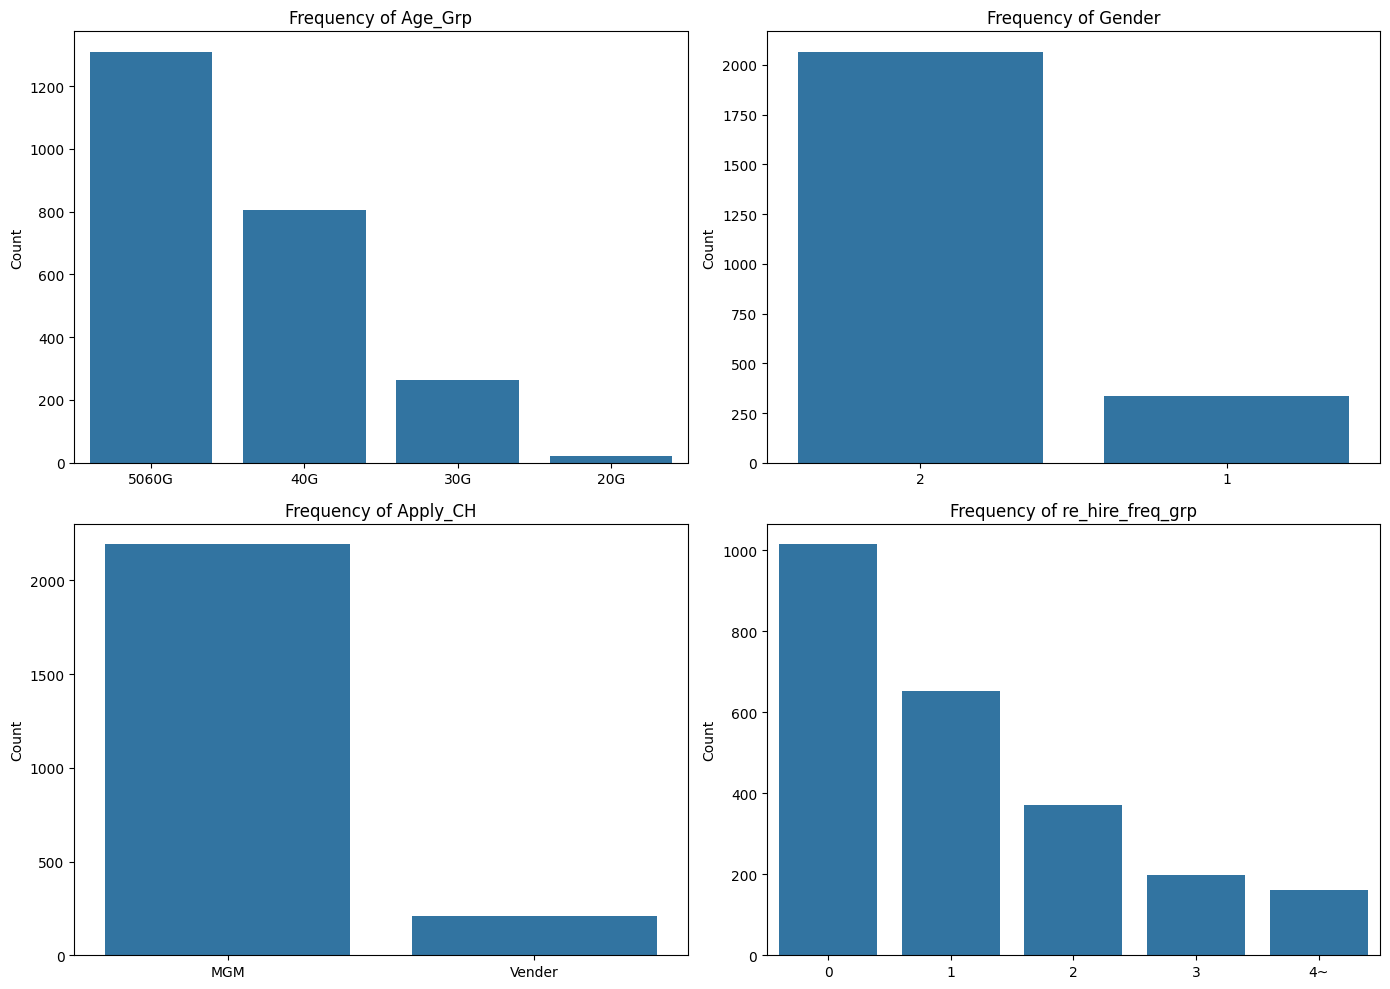

In [ ]:
cols = ['Age_Grp', 'Gender', 'Apply_CH', 're_hire_freq_grp']

# 2x2 서브플롯 설정
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(cols):
    sns.countplot(data=df, x=col, ax=axes[i], order=df[col].value_counts().index)
    axes[i].set_title(f'Frequency of {col}')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Count')

plt.tight_layout()
plt.show()

- 순서형(ordinal) 변수

In [ ]:
df.columns

Index(['Tgt_3YN', 'Age_Grp', 'Gender', 'Apply_CH', 're_hire_freq_grp', 'Q2',
       'Q7', 'Q8', 'Q18', 'Q22', 'Q38', 'rank_INDEX14', 'rank_INDEX18',
       'rank_INDEX23', 'rank_INDEX27', 'rank_INDEX28', 'rank_INDEX29',
       'rank_INDEX32', 'rank_INDEX44', 'rank_INDEX93', 'rank_AVG_AMT_6M'],
      dtype='object')

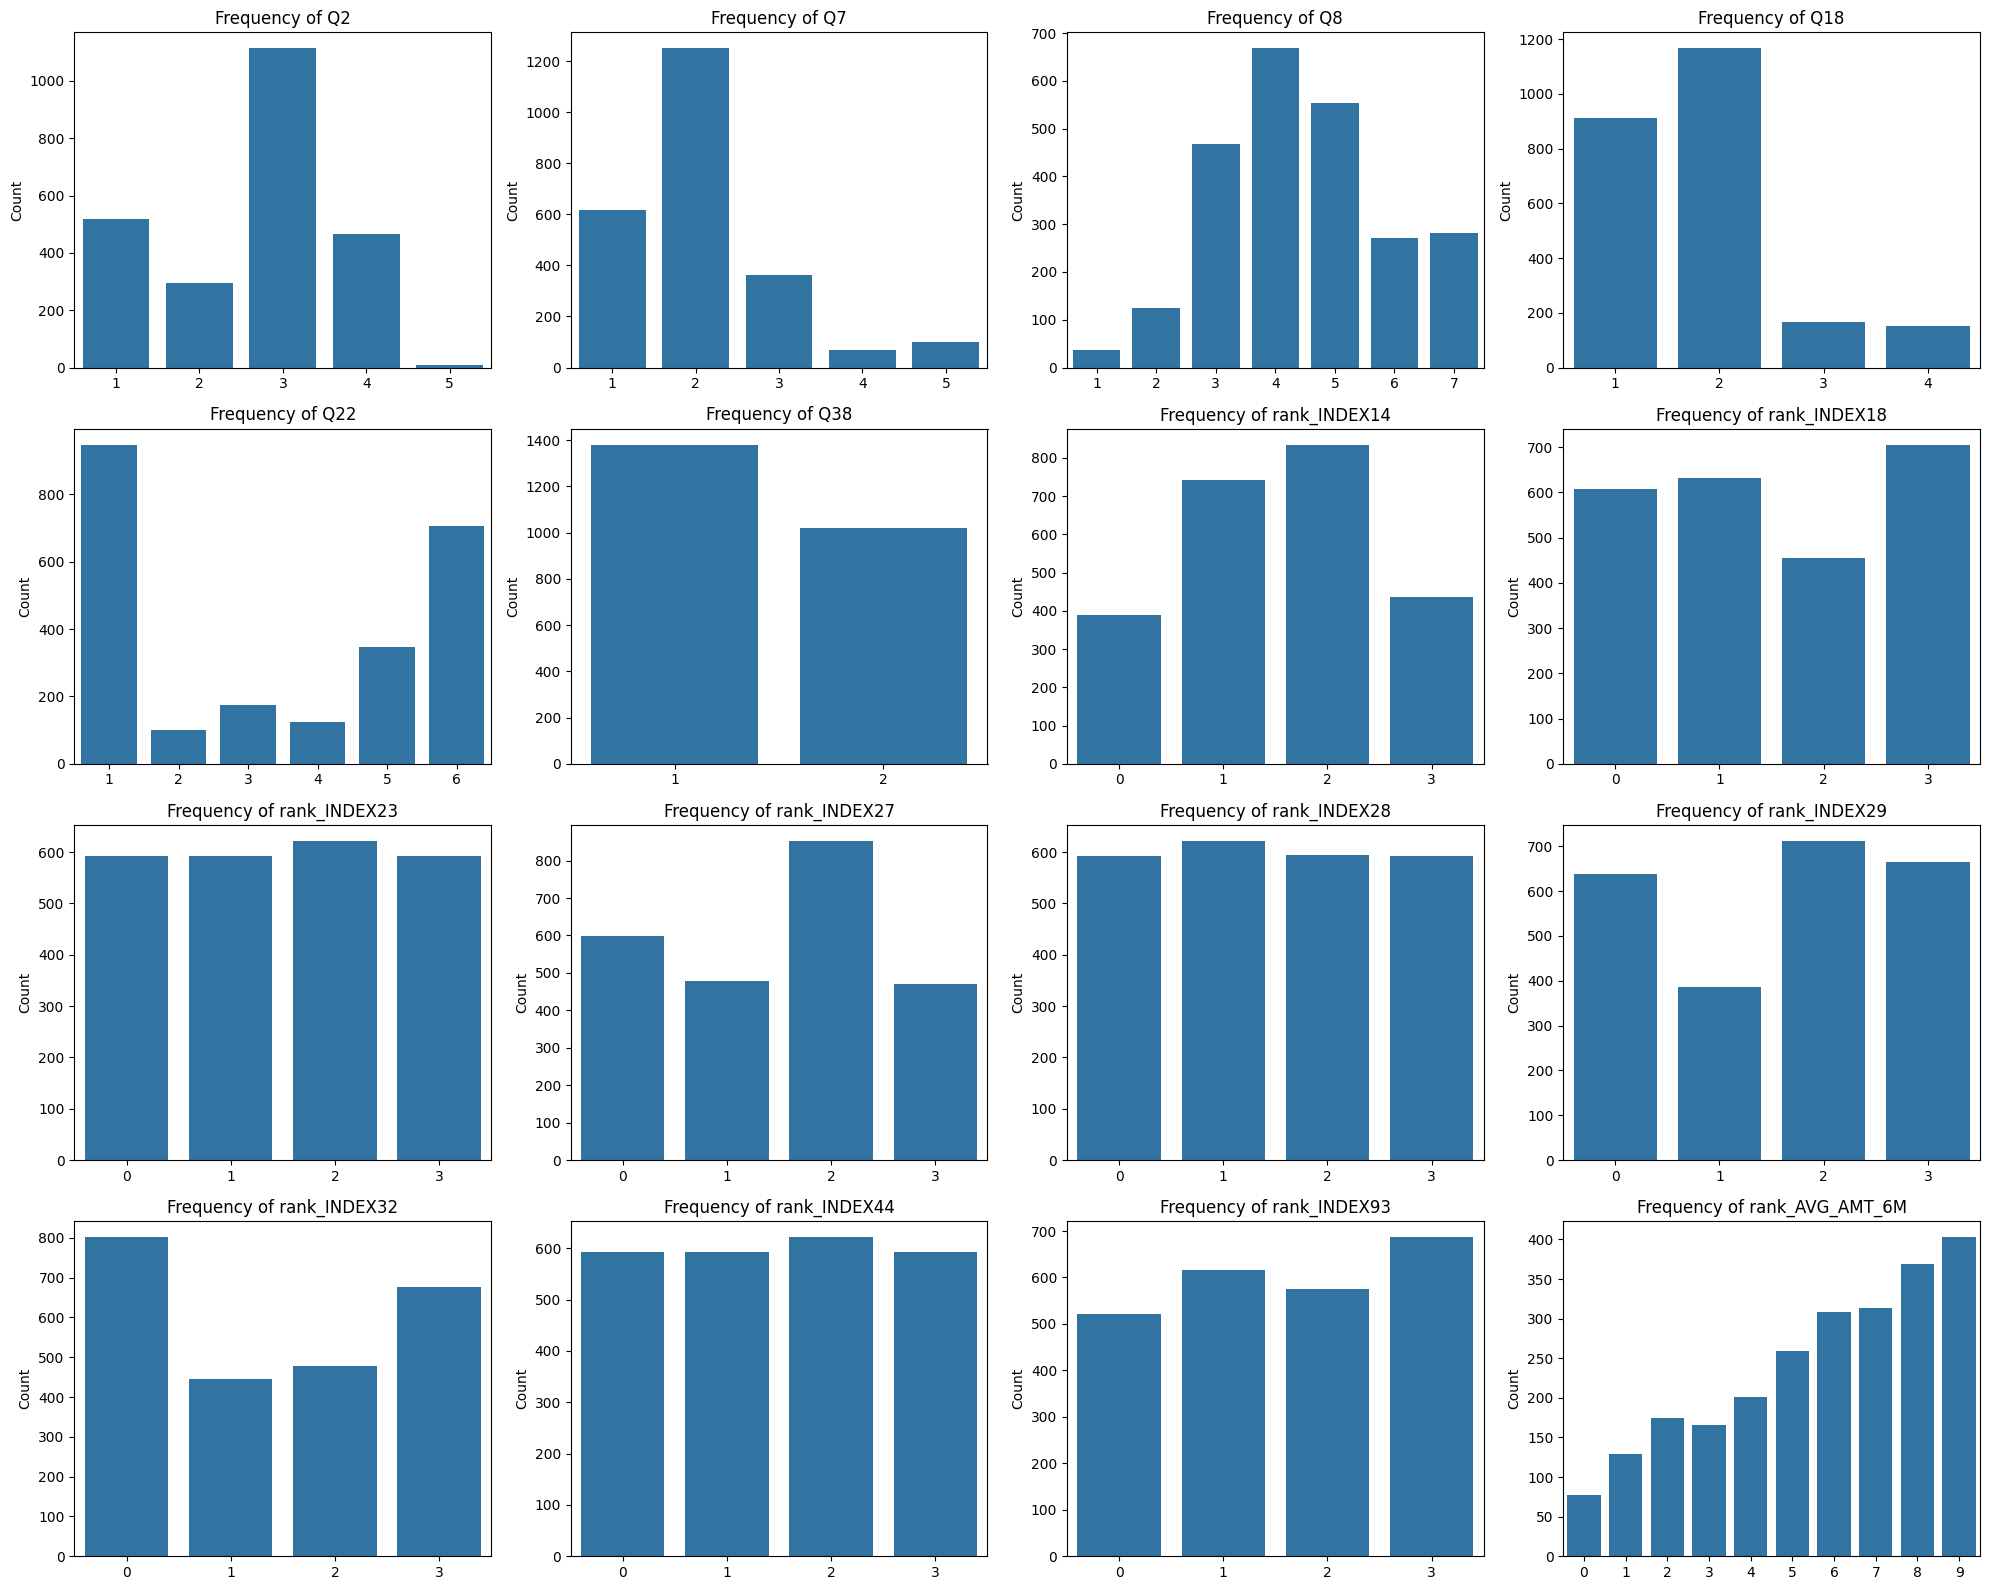

In [ ]:
ordinal_cols = [
    'Q2', 'Q7', 'Q8', 'Q18', 'Q22', 'Q38',
    'rank_INDEX14', 'rank_INDEX18', 'rank_INDEX23', 'rank_INDEX27',
    'rank_INDEX28', 'rank_INDEX29', 'rank_INDEX32', 'rank_INDEX44',
    'rank_INDEX93', 'rank_AVG_AMT_6M'
]

# 4x4 서브플롯 설정
fig, axes = plt.subplots(4, 4, figsize=(20, 16))
axes = axes.flatten()

for i, col in enumerate(ordinal_cols):
    # 순서형 변수이므로 인덱스 순서(오름차순)대로 정렬하여 그래프 출력
    sns.countplot(data=df, x=col, ax=axes[i], order=sorted(df[col].unique()))
    axes[i].set_title(f'Frequency of {col}')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Count')

plt.tight_layout()
plt.show()

### + 탐색적데이터분석(EDA)

- 범주형 변수(Object type): Age_Grp, Gender, Apply_CH, re_hire_freq_grp 범주별 Tgt_3YN(3개월이내 이탈여부) 비율

- 범주형-순서형 변수: Q2, Q7, Q8, Q18, Q38, rank_INDEX14, rank_INDEX18, rank_INDEX23, rank_INDEX27, rank_INDEX28, rank_INDEX29, rank_INDEX32, rank_INDEX44, rank_INDEX93, rank_AVG_AMT_6M 카테고리별 Tgt_3YN(3개월이내 이탈여부) 비율